# Marker pick-and-place, 10 runs (13 Nov 2026)

**Task.** Whiteboard marker from a taped spot on the table into a bowl:
home → pre_grasp → grasp → lift → pre_drop → place → home (`marker_sequence.yaml`, `bottle_test.launch.py`).

**Grip.** Gripper angle saved in the poses (closed at `grasp`, open at `place`), current cap 80
(~0.215 A). This is the **fixed-grip baseline** for GRACE claim 3 (adaptive vs fixed grip).

**Outcome noted at the bench.** 10/10 in the bowl, no visible slips.

**Questions.**
1. When does each pad make contact, and in which order?
2. How steady is the grip signal during lift and carry (baseline for a slip threshold)?
3. How fast does each pad return to zero after release?
4. Did every move finish cleanly?

In [1]:
import os, sys
from pathlib import Path
import numpy as np
sys.path.insert(0, str(Path.cwd()))
import flexigrasp_bag as fb

LOG_DIR = Path(os.environ.get("LOG_DIR", "~/flexigrasp_logs")).expanduser()
RUNS = [f"marker_{i:02d}" for i in range(1, 11)]

def latest_bag(label):
    """The last bag with this label (earlier failed starts of the same label are skipped)."""
    return sorted(LOG_DIR.glob(f"*_{label}_bag/*.db3"))[-1]

bags = {lab: latest_bag(lab) for lab in RUNS}
for lab, db in bags.items():
    print(lab, db.parent.name)

marker_01 20261113_224349_marker_01_bag
marker_02 20261113_224610_marker_02_bag
marker_03 20261113_224800_marker_03_bag
marker_04 20261113_224925_marker_04_bag
marker_05 20261113_225056_marker_05_bag
marker_06 20261113_225306_marker_06_bag
marker_07 20261113_225427_marker_07_bag
marker_08 20261113_225554_marker_08_bag
marker_09 20261113_225739_marker_09_bag
marker_10 20261113_225929_marker_10_bag


In [2]:
import matplotlib.pyplot as plt
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#1f1f1d", "#6b6b66", "#e6e6e1"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "legend.frameon": False, "figure.dpi": 110})

## 1. Did every move finish?

The runner times a move out after 15 s if any joint stays further than `move_tolerance_rad` (0.03)
from its target.

In [3]:
for lab, db in bags.items():
    st = fb.step_times(fb.read_steps(db))
    print(lab, "  ".join(f"{k.split(':')[1]}={v[2]}({v[1]-v[0]:.0f}s)" for k, v in st.items() if k.startswith("move")))

marker_01 pre_grasp=timeout(15s)  grasp=timeout(15s)  lift=timeout(15s)  pre_drop=timeout(15s)  place=timeout(15s)
marker_02 pre_grasp=ok(4s)  grasp=ok(3s)  lift=timeout(15s)  pre_drop=timeout(15s)  place=timeout(15s)
marker_03 pre_grasp=ok(4s)  grasp=ok(3s)  lift=timeout(15s)  pre_drop=timeout(15s)  place=timeout(15s)


marker_04 pre_grasp=ok(4s)  grasp=ok(3s)  lift=timeout(15s)  pre_drop=timeout(15s)  place=timeout(15s)
marker_05 pre_grasp=ok(4s)  grasp=ok(3s)  lift=timeout(15s)  pre_drop=timeout(15s)  place=timeout(15s)


marker_06 pre_grasp=ok(4s)  grasp=ok(3s)  lift=timeout(15s)  pre_drop=timeout(15s)  place=timeout(15s)
marker_07 pre_grasp=ok(4s)  grasp=ok(3s)  lift=timeout(15s)  pre_drop=timeout(15s)  place=timeout(15s)


marker_08 pre_grasp=ok(4s)  grasp=ok(3s)  lift=timeout(15s)  pre_drop=timeout(15s)  place=timeout(15s)
marker_09 pre_grasp=ok(4s)  grasp=ok(3s)  lift=timeout(15s)  pre_drop=timeout(15s)  place=timeout(15s)
marker_10 pre_grasp=ok(4s)  grasp=ok(3s)  lift=timeout(15s)  pre_drop=timeout(15s)  place=timeout(15s)


Which joint was out of tolerance at the end of each move (run 2 as an example):

In [4]:
db = bags["marker_02"]
J = fb.read_joint_states(db)
cmds = fb.read_commands(db)
for i, (t, target) in enumerate(cmds):
    t_end = cmds[i + 1][0] - 0.05 if i + 1 < len(cmds) else J["t"][-1]
    k = np.searchsorted(J["t"], t_end) - 1
    err = {n: J["pos"][k, J["names"].index(n)] - v for n, v in target.items()}
    worst = max(err, key=lambda n: abs(err[n]))
    print(f"command {i}: worst {worst:12s} {err[worst]:+.3f} rad (gripper target {target['gripper']:+.3f})")

command 0: worst joint4       -0.025 rad (gripper target -2.821)
command 1: worst joint2       -0.025 rad (gripper target -2.823)
command 2: worst gripper      -0.023 rad (gripper target -1.146)
command 3: worst gripper      -0.328 rad (gripper target -0.769)
command 4: worst gripper      -0.359 rad (gripper target -0.738)
command 5: worst joint3       +0.046 rad (gripper target -2.091)
command 6: worst joint4       -0.025 rad (gripper target -2.821)


`lift` and `pre_drop` were saved with the gripper at about −0.75, but the marker stops it at about
−1.17: those moves can never finish, so each waits the full 15 s while the gripper squeezes about
0.08 rad tighter. `place` misses by joint3 sag (0.046 > 0.03).

**Fix:** untick *Save gripper with pose* and Update `lift` and `pre_drop`; set `move_tolerance_rad: 0.05`.

## 2. Per-run metrics

In [5]:
def run_metrics(db, thresh=100):
    st = fb.step_times(fb.read_steps(db))
    J = fb.read_joint_states(db); gi = J["names"].index("gripper")
    tg, tl = st["move:grasp"][0], st["move:lift"][0]
    tp, tpl = st["move:pre_drop"][0], st["move:place"][0]
    t_rz = st["rezero"][1]
    med = lambda x, t, a, b: float(np.median(x[(t >= a) & (t < b)]))
    out = {}
    for s in ("left", "right"):
        p = fb.read_frames(db, s)
        x = p["pos"] - med(p["pos"], p["t"], t_rz, tg)        # counts above the zeroed pad
        k = np.flatnonzero((p["t"] >= tg) & (x > thresh))
        out[f"{s}_contact_s"] = p["t"][k[0]] - tg if len(k) else np.nan
        out[f"{s}_grasp"] = med(x, p["t"], tl - 0.5, tl)
        out[f"{s}_carry"] = med(x, p["t"], tpl - 2, tpl)
        m = (p["t"] >= tl) & (p["t"] < tpl)
        xs = x[m]
        out[f"{s}_carry_dip"] = np.percentile(xs, 1) / np.median(xs)          # lowest 1% vs typical
        out[f"{s}_drop_100ms"] = -(xs[10:] - xs[:-10]).min() / np.median(xs)  # largest 100 ms drop
        c = p["cxy"][m]
        out[f"{s}_centroid_range"] = np.nanmax(np.nanpercentile(c, 95, 0) - np.nanpercentile(c, 5, 0))
        k = np.flatnonzero((p["t"] >= tpl) & (x < thresh))
        out[f"{s}_release_s"] = p["t"][k[0]] - tpl if len(k) else np.nan
    out["grip_grasp_rad"] = med(J["pos"][:, gi], J["t"], tl - 0.5, tl)
    out["grip_carry_rad"] = med(J["pos"][:, gi], J["t"], tpl - 2, tpl)
    out["grip_current_A"] = med(J["eff"][:, gi], J["t"], tl - 0.5, tl)
    return out

metrics = {lab: run_metrics(db) for lab, db in bags.items()}
keys = list(next(iter(metrics.values())))
print("metric".ljust(22), " ".join(lab[-2:].rjust(7) for lab in metrics))
for k in keys:
    print(k.ljust(22), " ".join(f"{m[k]:7.3g}" for m in metrics.values()))

metric                      01      02      03      04      05      06      07      08      09      10
left_contact_s            2.06     2.1    2.14    2.11    2.09    2.05    2.04    2.03    2.08    2.03
left_grasp             1.43e+03 1.35e+03 1.4e+03 1.46e+03 1.66e+03 1.58e+03 1.7e+03 1.62e+03 1.69e+03 1.6e+03
left_carry             1.53e+03 1.62e+03 1.62e+03 1.67e+03 1.74e+03 1.64e+03 1.72e+03 1.66e+03 1.71e+03 1.69e+03
left_carry_dip           0.903   0.835   0.863   0.855   0.931   0.907    0.92   0.902   0.927   0.891
left_drop_100ms         0.0576  0.0746    0.06  0.0585  0.0542  0.0535  0.0541  0.0942  0.0698  0.0664
left_centroid_range     0.0917   0.103  0.0786  0.0561  0.0555  0.0887  0.0754   0.133  0.0713  0.0478
left_release_s           0.945   0.931   0.951    0.94   0.935   0.941   0.945   0.951   0.958   0.927
right_contact_s           2.05   0.951    1.01    2.15    2.07    2.01    2.03    2.04    2.03    2.01
right_grasp            1.21e+03     789     873     698 

## 3. One run in detail

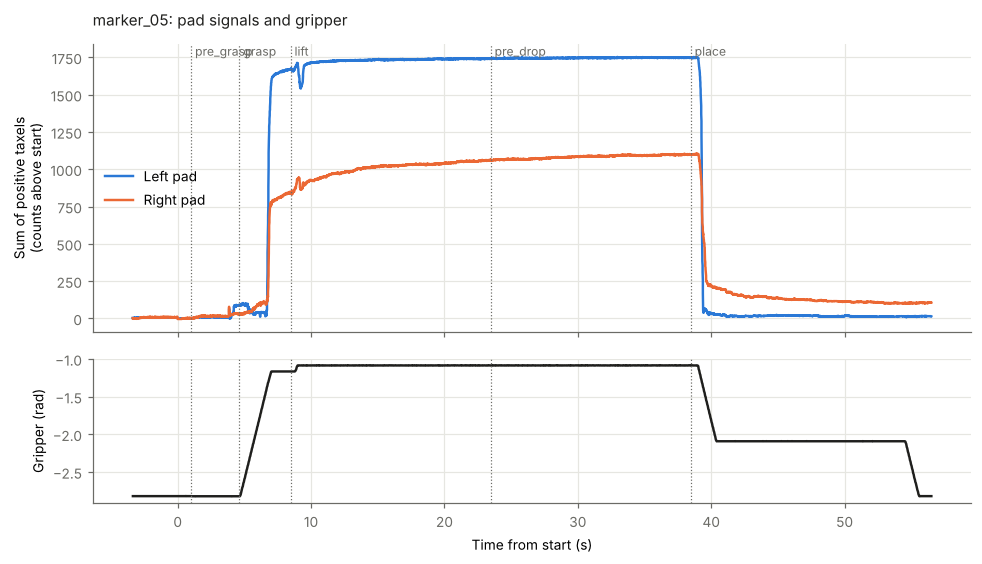

In [6]:
RUN = "marker_05"
db = bags[RUN]
ev = fb.step_times(fb.read_steps(db))
t0 = ev["move:pre_grasp"][0] - 1
fig, (a, b) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
for s, c in (("left", BLUE), ("right", ORANGE)):
    p = fb.read_frames(db, s)
    base = np.median(p["pos"][(p["t"] > t0) & (p["t"] < t0 + 1)])
    a.plot(p["t"] - t0, p["pos"] - base, color=c, lw=1.6, label=f"{s.capitalize()} pad")
J = fb.read_joint_states(db)
b.plot(J["t"] - t0, J["pos"][:, J["names"].index("gripper")], color=INK, lw=1.6)
for name in ("pre_grasp", "grasp", "lift", "pre_drop", "place"):
    t = ev[f"move:{name}"][0] - t0
    for ax in (a, b):
        ax.axvline(t, color=MUTED, lw=0.8, ls=":")
    a.text(t + 0.3, a.get_ylim()[1], name, fontsize=8, color=MUTED, va="top")
a.set_ylabel("Sum of positive taxels\n(counts above start)"); a.legend(loc="center left")
a.set_title(f"{RUN}: pad signals and gripper", loc="left", color=INK, fontsize=10, pad=12)
b.set_ylabel("Gripper (rad)"); b.set_xlabel("Time from start (s)")
fig.tight_layout()
fig.savefig(f"{RUN}.png", dpi=200)

## 4. Findings

- **10/10 success, no slips.** Gripper current sat at the cap (0.215 A) through every hold: a clean
  fixed-grip baseline.
- **Contact:** left pad 2.03–2.14 s after `grasp` starts in every run; the right pad touched ~1 s
  earlier in runs 2 and 3 (marker slightly off-centre).
- **Slip-threshold baseline:** during normal carrying the signal dips at most to 79–93% of its level,
  and the largest 100 ms drop is 2–9%. A slip alarm must trigger above ~10% per 100 ms.
- **Contact centre:** left moved < 0.15 taxel, right 0.1–0.7 taxel.
- **Release:** left back to zero ~0.94 s after `place` starts; the right pad keeps a residual of
  30–480 counts for many seconds.
- **Right pad:** ~0.6× the left for the same squeeze, rises slowly during holds, residual after release.
  Likely the velcro mounting; re-mount and coin-calibrate the right pad.
- **Sequence:** `lift`/`pre_drop` timed out every run (saved gripper tighter than the marker allows);
  `place` timed out on joint3 sag. Fixes in section 1.